# Lab 28-07 · Track Records, Schedules and Bench Depth

Companion to [chapter 28-07](../../chapters/28-07-evaluating-engineering-teams.md). Every part asks you to **predict first**, then run. All rates and values are the chapter's assumptions; the 14% base rate is from the 2024 survey [R-621].

In [1]:
import sys, math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, '.')
import teameval as te
A0, B0 = te.prior_params(0.14, 10)

## Part 1 · Shrinkage

**Predict:** the posterior mean after 5 successes in 5 projects.

42.7%


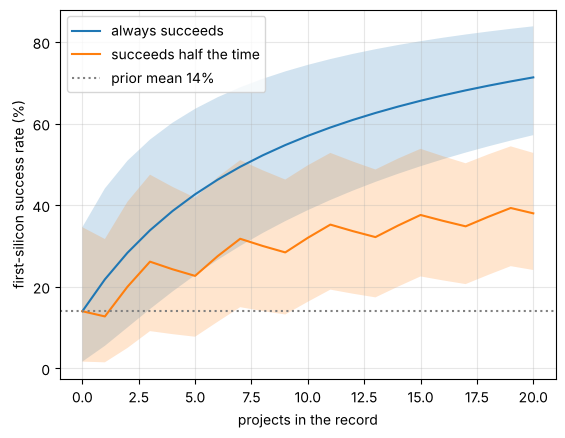

In [2]:
print(f"{100*te.posterior_mean(A0, B0, 5, 5):.1f}%")
n = np.arange(0, 21)
for frac, lab in ((1.0, 'always succeeds'), (0.5, 'succeeds half the time')):
    s = np.round(frac * n)
    m = [te.posterior_mean(A0, B0, si, ni) for si, ni in zip(s, n)]
    lo, hi = zip(*[te.credible_interval(A0, B0, si, ni) for si, ni in zip(s, n)])
    plt.plot(n, 100*np.array(m), label=lab)
    plt.fill_between(n, 100*np.array(lo), 100*np.array(hi), alpha=0.2)
plt.axhline(14, color='grey', ls=':', label='prior mean 14%')
plt.xlabel('projects in the record'); plt.ylabel('first-silicon success rate (%)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · Schedule forecast

Example 28-07.2's ratios: 1.25, 1.40, 1.30, 1.10.

**Predict:** the P90 duration for a 24-month plan.

P90 = 34.4 months; on time 1.16%


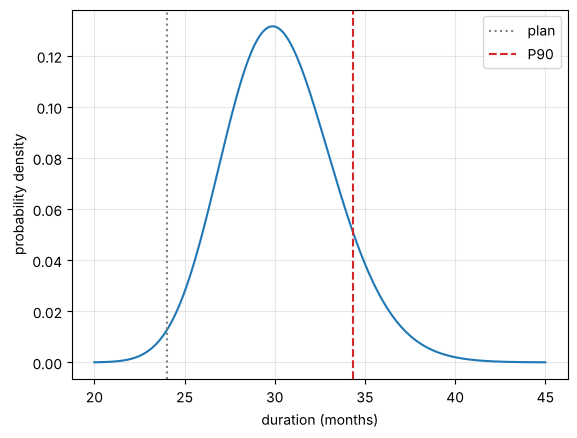

In [3]:
mu, sd = te.schedule_fit([1.25, 1.40, 1.30, 1.10])
print(f"P90 = {te.duration_quantile(24, mu, sd, 0.9):.1f} months; on time {100*te.on_time_probability(mu, sd):.2f}%")
t = np.linspace(20, 45, 300)
pdf = stats.lognorm.pdf(t, s=sd, scale=24*math.exp(mu))
plt.plot(t, pdf); plt.axvline(24, color='grey', ls=':', label='plan')
plt.axvline(te.duration_quantile(24, mu, sd, 0.9), color='C3', ls='--', label='P90')
plt.xlabel('duration (months)'); plt.ylabel('probability density'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 3 · Bench depth over time

**Predict:** the probability of losing a capability held by two people over three years at 12% a year.

10.1%


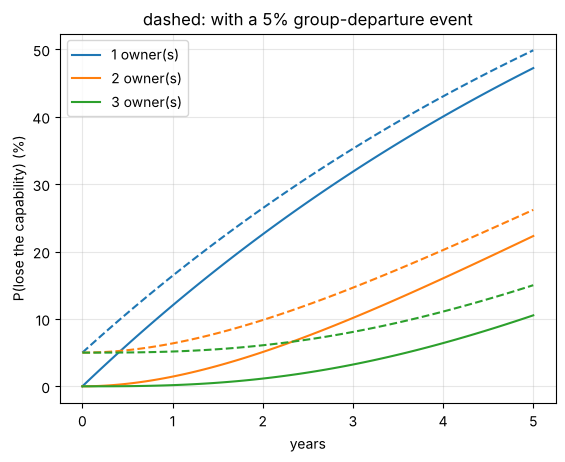

In [4]:
print(f"{100*te.capability_loss(te.horizon_rate(0.12, 3), 2):.1f}%")
yrs = np.linspace(0, 5, 101)
for k in (1, 2, 3):
    plt.plot(yrs, [100*te.capability_loss(te.horizon_rate(0.12, y), k) for y in yrs], label=f'{k} owner(s)')
    plt.plot(yrs, [100*te.capability_loss(te.horizon_rate(0.12, y), k, group_event=0.05) for y in yrs], ls='--', color=f'C{k-1}')
plt.xlabel('years'); plt.ylabel('P(lose the capability) (%)'); plt.title('dashed: with a 5% group-departure event')
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · Retention

Example 28-07.5: 60 engineers at $1.5M each; retention 70% without a package.

**Predict:** the break-even package cost for a 15-point retention gain.

break-even cost: $13.5M


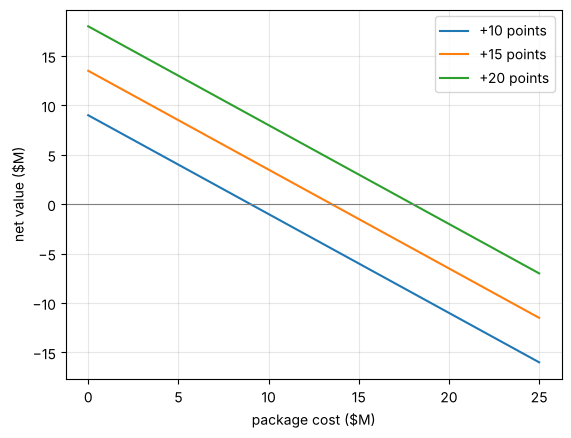

In [5]:
gain = te.retained_value(60, 1.5, 0.85) - te.retained_value(60, 1.5, 0.70)
print(f"break-even cost: ${gain:.1f}M")
cost = np.linspace(0, 25, 101)
for d in (0.10, 0.15, 0.20):
    plt.plot(cost, te.retained_value(60, 1.5, d) - cost, label=f'+{int(100*d)} points')
plt.axhline(0, color='grey', lw=0.8)
plt.xlabel('package cost ($M)'); plt.ylabel('net value ($M)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()